# Análise exploratória — readmissão hospitalar em < 30 dias

**Pergunta:** quais características da internação e do paciente diabético se associam
à readmissão em menos de 30 dias?

**Dados:** `data-processed/dataset_modelo.csv`, gerado por `etl/pipeline.py`
(99.340 internações elegíveis — óbitos e hospice já removidos).

**Como ler os gráficos:** cada barra é a **taxa de readmissão < 30 dias** naquele grupo.
A linha tracejada é a taxa geral. As barras finas pretas são o intervalo de confiança de 95%
(grupos pequenos têm intervalo largo — não tire conclusões deles).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURAS = RAIZ / "reports" / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(RAIZ / "data-processed" / "dataset_modelo.csv")
TAXA_GERAL = df["readmit_30"].mean()

# Estilo: uma cor so (a metrica e sempre a mesma), grade discreta.
AZUL, TINTA, TINTA_2, SUPERFICIE = "#2a78d6", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE,
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": TINTA_2,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "text.color": TINTA,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 11, "axes.titlesize": 13,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110,
})

print(f"Internacoes: {len(df):,} | Pacientes: {df['patient_nbr'].nunique():,}")
print(f"Taxa geral de readmissao < 30 dias: {TAXA_GERAL:.1%}")

Internacoes: 99,340 | Pacientes: 69,987
Taxa geral de readmissao < 30 dias: 11.4%


In [2]:
def taxa_por(coluna, ordem=None, min_n=100):
    """Taxa de readmissao por grupo, com IC 95% de Wilson."""
    g = df.groupby(coluna)["readmit_30"].agg(n="size", eventos="sum")
    g = g[g["n"] >= min_n]
    p = g["eventos"] / g["n"]
    z = 1.96
    centro = (p + z**2 / (2 * g["n"])) / (1 + z**2 / g["n"])
    meia = z * np.sqrt(p * (1 - p) / g["n"] + z**2 / (4 * g["n"] ** 2)) / (1 + z**2 / g["n"])
    g["taxa"], g["ic_inf"], g["ic_sup"] = p, centro - meia, centro + meia
    if ordem is not None:
        g = g.reindex([o for o in ordem if o in g.index])
    return g


def grafico_taxa(tabela, titulo, xlabel="", horizontal=False, arquivo=None):
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(tabela) + 1.8) if horizontal else (8, 4.2), layout="constrained")
    rotulos = [str(i).replace("_", " ") for i in tabela.index]
    pos = np.arange(len(tabela))
    erro = [tabela["taxa"] - tabela["ic_inf"], tabela["ic_sup"] - tabela["taxa"]]
    if horizontal:
        ax.barh(pos, tabela["taxa"], height=0.6, color=AZUL)
        ax.errorbar(tabela["taxa"], pos, xerr=erro, fmt="none", ecolor=TINTA, elinewidth=1, capsize=0)
        ax.axvline(TAXA_GERAL, color=TINTA_2, linestyle="--", linewidth=1)
        ax.set_yticks(pos, rotulos)
        ax.invert_yaxis()
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
        ax.grid(axis="y", visible=False)
        ax.set_xlabel("Taxa de readmissão < 30 dias")
    else:
        ax.bar(pos, tabela["taxa"], width=0.6, color=AZUL)
        ax.errorbar(pos, tabela["taxa"], yerr=erro, fmt="none", ecolor=TINTA, elinewidth=1, capsize=0)
        ax.axhline(TAXA_GERAL, color=TINTA_2, linestyle="--", linewidth=1)
        ax.set_xticks(pos, rotulos)
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
        ax.grid(axis="x", visible=False)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Taxa de readmissão < 30 dias")
    # Rotulo so nos extremos (maior e menor taxa) e na linha de referencia.
    for i in {tabela["taxa"].values.argmax(), tabela["taxa"].values.argmin()}:
        v = tabela["taxa"].iloc[i]
        if horizontal:
            ax.annotate(f"{v:.1%}", (tabela["ic_sup"].iloc[i], i), xytext=(4, 0),
                        textcoords="offset points", va="center", fontsize=10, color=TINTA)
        else:
            ax.annotate(f"{v:.1%}", (i, tabela["ic_sup"].iloc[i]), xytext=(0, 4),
                        textcoords="offset points", ha="center", fontsize=10, color=TINTA)
    fig.suptitle(titulo, x=0.01, ha="left", fontsize=13, fontweight="bold")
    ax.set_title(f"Linha tracejada = taxa geral ({TAXA_GERAL:.1%}) · barras pretas = IC 95%",
                 fontsize=9, fontweight="normal", color=TINTA_2, loc="left")
    if arquivo:
        fig.savefig(FIGURAS / arquivo, dpi=150, bbox_inches="tight")
    plt.show()
    return tabela[["n", "taxa"]].style.format({"n": "{:,}", "taxa": "{:.1%}"})

## 1. Visão geral

- Só **~11% das internações** terminam em readmissão < 30 dias → classes **desbalanceadas**.
  Um modelo que sempre diz "não volta" acerta 89% e não serve para nada. Por isso o modelo
  será avaliado por *recall*, ROC-AUC e PR-AUC, não por acurácia.
- Muitos pacientes aparecem mais de uma vez. Isso exige separar treino e teste **por paciente**.

In [3]:
por_paciente = df.groupby("patient_nbr").size()
pd.Series({
    "Internacoes": f"{len(df):,}",
    "Pacientes": f"{len(por_paciente):,}",
    "Pacientes com 2+ internacoes": f"{(por_paciente > 1).sum():,} ({(por_paciente > 1).mean():.0%})",
    "Readmissoes < 30 dias": f"{df['readmit_30'].sum():,} ({TAXA_GERAL:.1%})",
}).to_frame("valor")

,valor
Internacoes,"99,340"
Pacientes,"69,987"
Pacientes com 2+ internacoes,"16,341 (23%)"
Readmissoes < 30 dias,"11,314 (11.4%)"


## 2. Histórico de uso do serviço de saúde

A hipótese clínica: quem já interna com frequência tem doença menos controlada, mais
comorbidades e maior fragilidade — e volta mais.

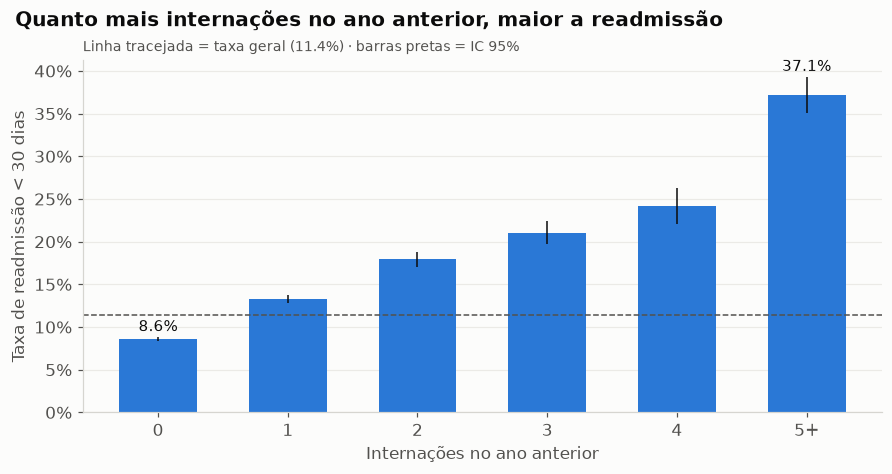

,n,taxa
internacoes_previas,,
0,"66,242",8.6%
1,"18,984",13.3%
2,"7,300",17.9%
3,"3,271",21.0%
4,"1,574",24.1%
5+,"1,969",37.1%


In [4]:
df["internacoes_previas"] = df["number_inpatient"].clip(upper=5).astype(str).replace("5", "5+")
grafico_taxa(
    taxa_por("internacoes_previas", ordem=["0", "1", "2", "3", "4", "5+"]),
    "Quanto mais internações no ano anterior, maior a readmissão",
    xlabel="Internações no ano anterior", arquivo="01_internacoes_previas.png",
)

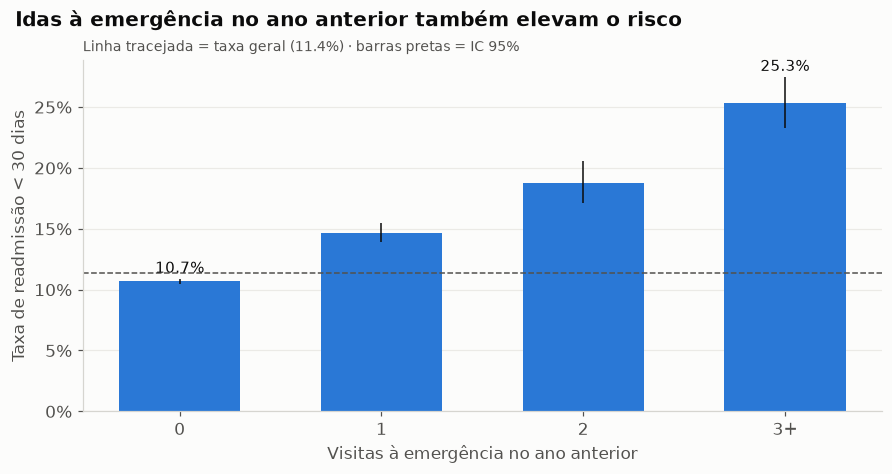

,n,taxa
emergencias_previas,,
0,"88,246",10.7%
1,"7,474",14.7%
2,"1,984",18.8%
3+,"1,636",25.3%


In [5]:
df["emergencias_previas"] = df["number_emergency"].clip(upper=3).astype(str).replace("3", "3+")
grafico_taxa(
    taxa_por("emergencias_previas", ordem=["0", "1", "2", "3+"]),
    "Idas à emergência no ano anterior também elevam o risco",
    xlabel="Visitas à emergência no ano anterior", arquivo="02_emergencias_previas.png",
)

**Leitura:** é o sinal mais forte do dataset. Pacientes com 5+ internações no ano anterior
voltam em < 30 dias cerca de **4 vezes mais** do que quem não teve nenhuma.

## 3. Destino da alta

Para onde o paciente vai depois da alta diz muito sobre a gravidade e a rede de cuidado.

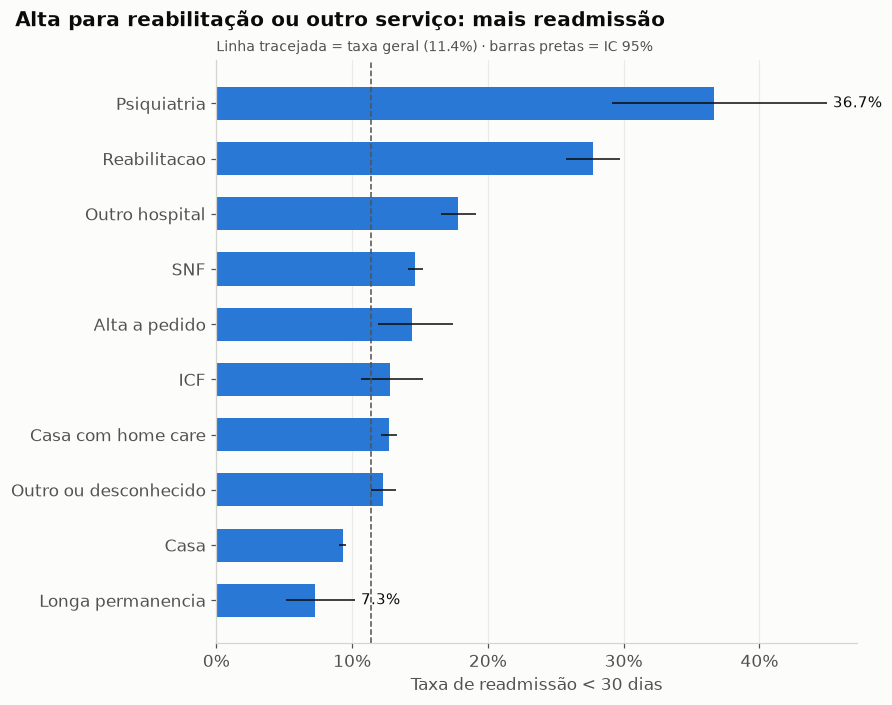

,n,taxa
destino_alta,,
Psiquiatria,139,36.7%
Reabilitacao,"1,992",27.7%
Outro_hospital,"3,312",17.8%
SNF,"13,954",14.7%
Alta_a_pedido,623,14.4%
ICF,815,12.8%
Casa_com_home_care,"13,010",12.7%
Outro_ou_desconhecido,"4,851",12.3%
Casa,"60,232",9.3%


In [6]:
grafico_taxa(
    taxa_por("destino_alta").sort_values("taxa", ascending=False),
    "Alta para reabilitação ou outro serviço: mais readmissão",
    horizontal=True, arquivo="03_destino_alta.png",
)

**Leitura:** alta para casa tem a menor taxa. Transferência para reabilitação, SNF
(*skilled nursing facility*) ou outro hospital indica paciente mais dependente.

## 4. Manejo do diabetes

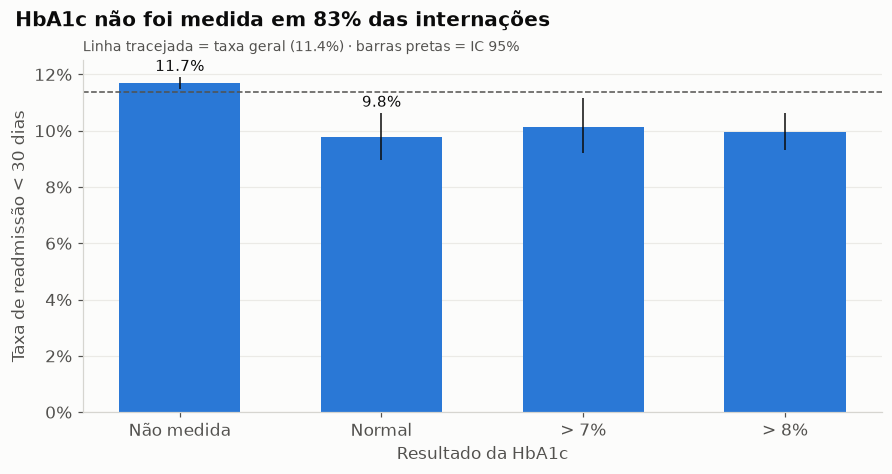

,n,taxa
hba1c,,
Não medida,"82,506",11.7%
Normal,"4,922",9.8%
> 7%,"3,775",10.1%
> 8%,"8,137",9.9%


In [7]:
nomes_hba1c = {"Nao_medido": "Não medida", "Norm": "Normal", ">7": "> 7%", ">8": "> 8%"}
df["hba1c"] = df["A1Cresult"].map(nomes_hba1c)
grafico_taxa(
    taxa_por("hba1c", ordem=["Não medida", "Normal", "> 7%", "> 8%"]),
    "HbA1c não foi medida em 83% das internações",
    xlabel="Resultado da HbA1c", arquivo="04_hba1c.png",
)

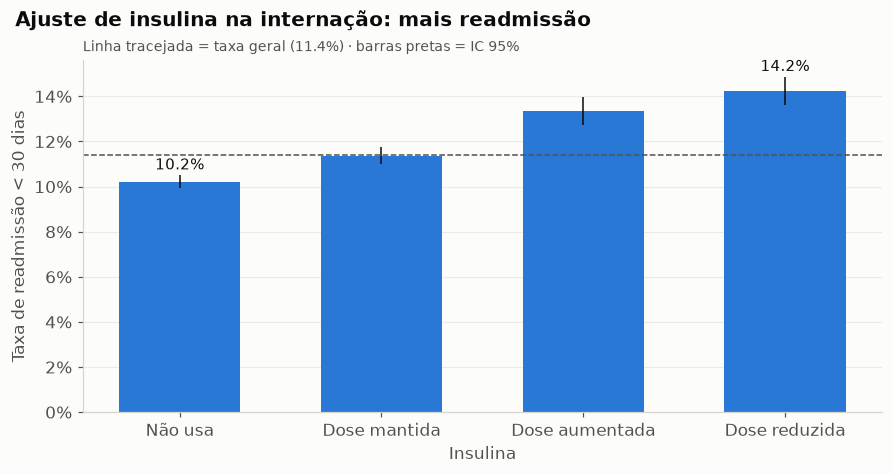

,n,taxa
insulina,,
Não usa,"46,376",10.2%
Dose mantida,"30,069",11.4%
Dose aumentada,"10,987",13.3%
Dose reduzida,"11,908",14.2%


In [8]:
nomes_insulina = {"No": "Não usa", "Steady": "Dose mantida", "Up": "Dose aumentada", "Down": "Dose reduzida"}
df["insulina"] = df["insulin"].map(nomes_insulina)
grafico_taxa(
    taxa_por("insulina", ordem=list(nomes_insulina.values())),
    "Ajuste de insulina na internação: mais readmissão",
    xlabel="Insulina", arquivo="05_insulina.png",
)

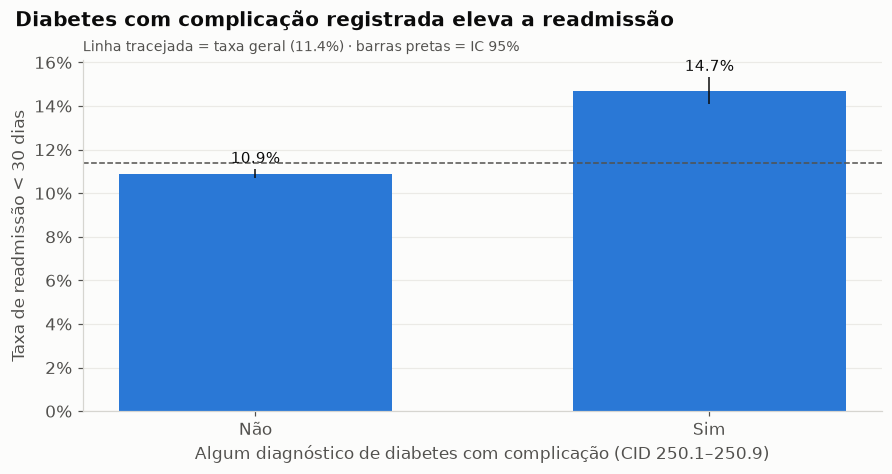

,n,taxa
diabetes_complicacao,,
Não,"86,522",10.9%
Sim,"12,818",14.7%


In [9]:
df["diabetes_complicacao"] = df["diabetes_complicado"].map({0: "Não", 1: "Sim"})
grafico_taxa(
    taxa_por("diabetes_complicacao", ordem=["Não", "Sim"]),
    "Diabetes com complicação registrada eleva a readmissão",
    xlabel="Algum diagnóstico de diabetes com complicação (CID 250.1–250.9)",
    arquivo="06_diabetes_complicado.png",
)

**Leitura:**
- A HbA1c — o principal exame de controle glicêmico — **não foi medida na grande maioria das
  internações**. Quando foi medida, a taxa de readmissão é menor, mesmo com resultado alterado:
  medir provavelmente reflete um cuidado mais atento ao diabetes (é a tese do artigo original,
  Strack et al., 2014).
- Ajustar a insulina (para cima ou para baixo) marca um paciente descompensado.
- Diabetes com complicação registrada (renal, oftalmológica, neurológica, circulatória…)
  aumenta a readmissão.

## 5. Internação e perfil do paciente

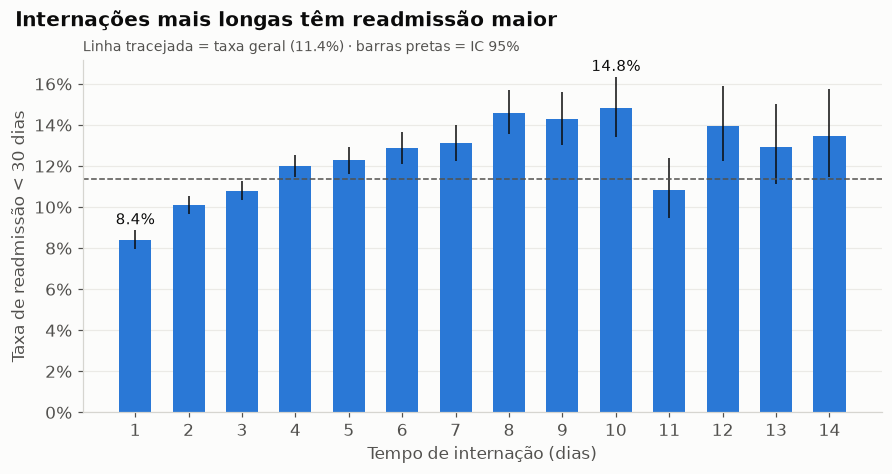

,n,taxa
time_in_hospital,,
1,"13,822",8.4%
2,"16,891",10.1%
3,"17,432",10.8%
4,"13,684",12.0%
5,"9,749",12.3%
6,"7,355",12.9%
7,"5,696",13.1%
8,"4,270",14.6%
9,"2,879",14.3%


In [10]:
grafico_taxa(
    taxa_por("time_in_hospital"),
    "Internações mais longas têm readmissão maior",
    xlabel="Tempo de internação (dias)", arquivo="07_tempo_internacao.png",
)

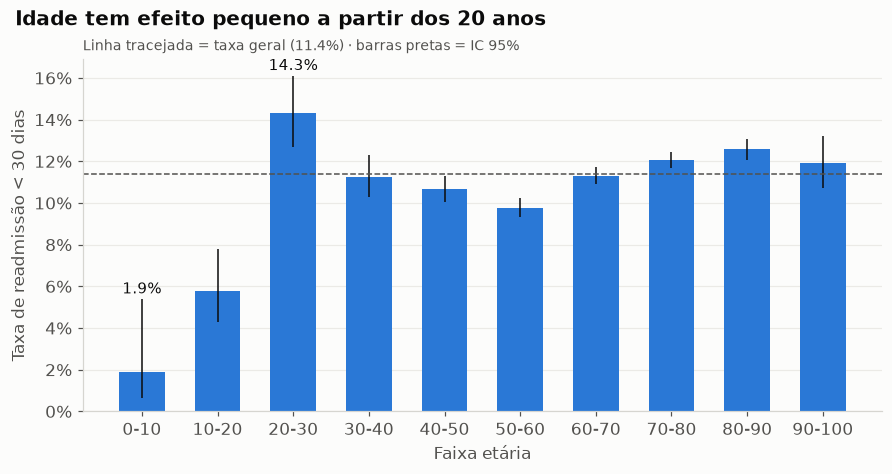

,n,taxa
faixa_etaria,,
0-10,160,1.9%
10-20,690,5.8%
20-30,"1,649",14.3%
30-40,"3,764",11.3%
40-50,"9,607",10.7%
50-60,"17,060",9.8%
60-70,"22,058",11.3%
70-80,"25,329",12.1%
80-90,"16,434",12.6%


In [11]:
faixas = {5: "0-10", 15: "10-20", 25: "20-30", 35: "30-40", 45: "40-50",
          55: "50-60", 65: "60-70", 75: "70-80", 85: "80-90", 95: "90-100"}
df["faixa_etaria"] = df["idade"].map(faixas)
grafico_taxa(
    taxa_por("faixa_etaria", ordem=list(faixas.values())),
    "Idade tem efeito pequeno a partir dos 20 anos",
    xlabel="Faixa etária", arquivo="08_idade.png",
)

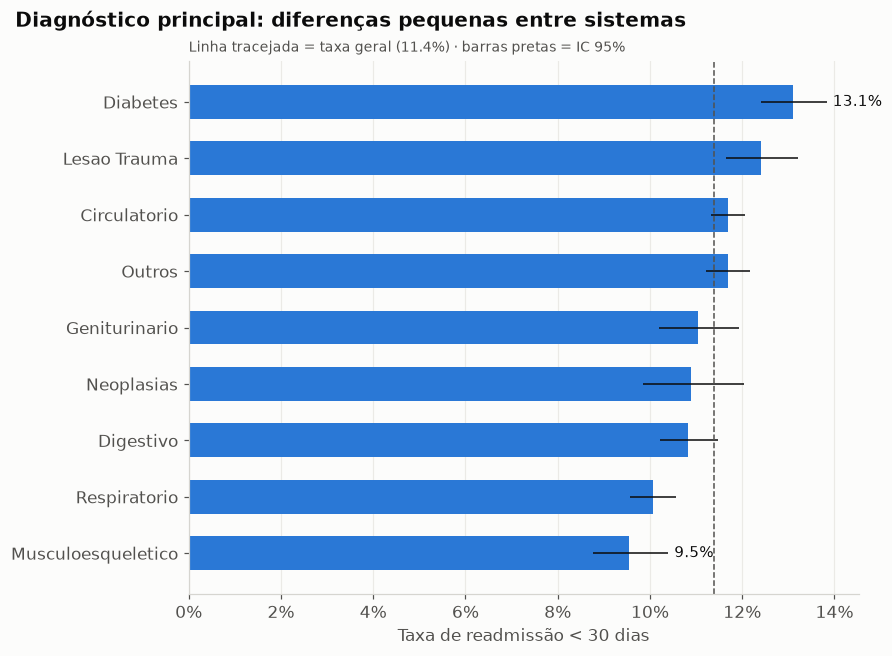

,n,taxa
diag_1_grupo,,
Diabetes,"8,661",13.1%
Lesao_Trauma,"6,851",12.4%
Circulatorio,"29,680",11.7%
Outros,"17,793",11.7%
Geniturinario,"5,002",11.0%
Neoplasias,"3,131",10.9%
Digestivo,"9,333",10.8%
Respiratorio,"13,934",10.1%
Musculoesqueletico,"4,935",9.5%


In [12]:
grafico_taxa(
    taxa_por("diag_1_grupo").sort_values("taxa", ascending=False),
    "Diagnóstico principal: diferenças pequenas entre sistemas",
    horizontal=True, arquivo="09_diagnostico_principal.png",
)

## 6. Variáveis numéricas

Média de cada variável entre quem foi e quem não foi readmitido.

In [13]:
numericas = ["number_inpatient", "number_emergency", "number_outpatient", "total_visitas_previas",
             "time_in_hospital", "num_medications", "num_lab_procedures", "num_procedures",
             "number_diagnoses", "n_medicamentos_diabetes", "n_doses_alteradas", "idade"]
comparacao = df.groupby("readmit_30")[numericas].mean().T
comparacao.columns = ["Não readmitido", "Readmitido < 30d"]
comparacao["Razão"] = comparacao["Readmitido < 30d"] / comparacao["Não readmitido"]
comparacao.sort_values("Razão", ascending=False).style.format("{:.2f}")

,Não readmitido,Readmitido < 30d,Razão
number_inpatient,0.55,1.22,2.20
number_emergency,0.18,0.36,2.01
total_visitas_previas,1.09,2.02,1.84
number_outpatient,0.36,0.44,1.21
n_doses_alteradas,0.28,0.34,1.19
time_in_hospital,4.33,4.77,1.10
num_medications,15.86,16.91,1.07
number_diagnoses,7.36,7.69,1.04
num_lab_procedures,42.74,44.22,1.03
idade,65.62,66.73,1.02


## 7. Resumo dos achados

| # | Achado | Implicação |
|---|---|---|
| 1 | **Internações e emergências prévias** são o fator mais forte (8,6% → 37% com 5+ internações) | Identificar "usuários frequentes" na admissão |
| 2 | **Destino da alta** importa: reabilitação e transferências voltam mais que alta para casa | Planejamento de alta e transição de cuidado |
| 3 | **HbA1c não é medida em 83% das internações**, e quem mede tem readmissão menor | Oportunidade simples de protocolo |
| 4 | **Ajuste de insulina** e **diabetes com complicação** marcam paciente descompensado | Reforçar educação em saúde na alta |
| 5 | Idade, diagnóstico principal e tipo de admissão têm efeito **pequeno** | Não devem ser o foco de uma intervenção |
| 6 | Classe desbalanceada (11%) e pacientes repetidos | Métricas certas e split por paciente no modelo |

> ✍️ **Para a autora:** acrescente aqui a sua leitura como enfermeira — por exemplo, o que
> a falta de HbA1c significa na rotina da internação, e que intervenções de enfermagem na alta
> (educação sobre insulina, retorno ambulatorial agendado, contato telefônico) poderiam reduzir
> a readmissão desses grupos.

**Próximo passo:** `02_modelo.ipynb` — prever a readmissão com esses fatores.